In [11]:
# 1. IMPORT LIBRARIES
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [12]:
# 2. LOAD DATA
df = pd.read_csv("telco_churn_dirty.csv")

# 1. Data Understanding 

In [14]:
df.head()

,CustomerID,Gender,SeniorCitizen,TenureMonths,ContractType,InternetService,TechSupport,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5341-IJCHJ,Male,0,39,Month-to-Month,DSL,Yes,No,Electronic Check,44.17,1708.56,No
1,9654-BXTPK,Female,0,41,One Year,No,No,Yes,Electronic Check,18.0,666.5,Yes
2,3449-BSHXE,Male,1,69,Month-to-Month,Fiber Optic,No,No,Bank Transfer,69.17,4990.33,No
3,7983-GAZGE,Female,0,35,Month-to-Month,DSL,No,No,Bank Transfer,60.19,2154.59,No
4,3190-OLBHW,MALE,0,55,Two Year,DSL,No,Yes,Mailed Check,57.4,2999.28,No


In [15]:
df.tail()

,CustomerID,Gender,SeniorCitizen,TenureMonths,ContractType,InternetService,TechSupport,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
5495,9791-PONKO,Female,0,3,Two Year,No,No Internet,Yes,Credit Card,25.79,71.17,No
5496,8137-DPGGB,Male,0,36,Two Year,No,Yes,No,Credit Card,18.0,660.13,Yes
5497,5467-JDKSS,Male,0,22,Two Year,Fiber Optic,NaN,Yes,Bank Transfer,68.31,1554.09,No
5498,8099-JMLDA,Male,0,4,Month-to-Month,No,No,No,Credit Card,21.46,89.0,Yes
5499,5550-CTRYK,Female,0,71,Month-to-Month,No,No,NaN,Electronic Check,22.12,1567.5,No


In [16]:
df.shape

(5500, 12)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   CustomerID        5500 non-null   object
 1   Gender            5389 non-null   object
 2   SeniorCitizen     5500 non-null   int64 
 3   TenureMonths      5500 non-null   int64 
 4   ContractType      5457 non-null   object
 5   InternetService   5452 non-null   object
 6   TechSupport       5362 non-null   object
 7   PaperlessBilling  5419 non-null   object
 8   PaymentMethod     5292 non-null   object
 9   MonthlyCharges    5388 non-null   object
 10  TotalCharges      5500 non-null   object
 11  Churn             5500 non-null   object
dtypes: int64(2), object(10)
memory usage: 515.8+ KB


In [18]:
df.isnull().sum()

CustomerID            0
Gender              111
SeniorCitizen         0
TenureMonths          0
ContractType         43
InternetService      48
TechSupport         138
PaperlessBilling     81
PaymentMethod       208
MonthlyCharges      112
TotalCharges          0
Churn                 0
dtype: int64

In [19]:
print(df.columns.tolist())

['CustomerID', 'Gender', 'SeniorCitizen', 'TenureMonths', 'ContractType', 'InternetService', 'TechSupport', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [20]:
print(df.select_dtypes(include="number").columns.tolist())

['SeniorCitizen', 'TenureMonths']


In [21]:
print(df.select_dtypes(include="object").columns.tolist())

['CustomerID', 'Gender', 'ContractType', 'InternetService', 'TechSupport', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [22]:
print("\nNUMBER OF UNIQUE VALUES")
print(df.nunique())


NUMBER OF UNIQUE VALUES
CustomerID          5463
Gender                 4
SeniorCitizen          2
TenureMonths          76
ContractType           9
InternetService        6
TechSupport            3
PaperlessBilling       2
PaymentMethod         11
MonthlyCharges      3810
TotalCharges        5372
Churn                  2
dtype: int64


# 2. Data Cleaning

In [24]:
# checking duplicates first 
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 37


In [25]:
# see duplicate value
df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist())

,CustomerID,Gender,SeniorCitizen,TenureMonths,ContractType,InternetService,TechSupport,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
307,1626-MZEYG,NaN,0,9,Month-to-Month,Fiber Optic,Yes,Yes,Electronic Check,NaN,707.98,No
5383,1626-MZEYG,NaN,0,9,Month-to-Month,Fiber Optic,Yes,Yes,Electronic Check,NaN,707.98,No
465,1638-MXRBY,Male,0,13,One Year,DSL,Yes,Yes,NaN,45.16,591.86,No
1512,1638-MXRBY,Male,0,13,One Year,DSL,Yes,Yes,NaN,45.16,591.86,No
5059,2112-XHSTT,Female,0,58,Month-to-Month,No,Yes,Yes,Mailed Check,27.18,1466.13,No
...,...,...,...,...,...,...,...,...,...,...,...,...
1181,9310-RHITX,Female,1,43,One Year,Fiber Optic,No,Yes,Credit Card,99.44,4051.87,No
3935,9412-BVHGH,Female,0,19,One Year,DSL,Yes,Yes,Electronic Check,NaN,1103.8,No
5053,9412-BVHGH,Female,0,19,One Year,DSL,Yes,Yes,Electronic Check,NaN,1103.8,No
3251,9903-FZAJV,Female,0,42,Month-to-Month,No,No,Yes,Mailed Check,$18.00,741.05,No


In [26]:
# Observed Duplicate Drop them
df = df.drop_duplicates()
print("New shape:", df.shape)

New shape: (5463, 12)


## 1. CustomerID Column

In [28]:
#first check null value and duplicate value present in this table
print("Nulls:", df['CustomerID'].isna().sum())
print("Duplicate CustomerIDs:", df['CustomerID'].duplicated().sum())

Nulls: 0
Duplicate CustomerIDs: 0


## 2. Gender Column

In [30]:
#first check this column contain which type of value and null value
print(df['Gender'].value_counts(dropna=False))

Gender
Female    2642
Male      2604
NaN        109
MALE        64
FEMALE      44
Name: count, dtype: int64


In [31]:
#casing duplicates (MALE/FEMALE vs Male/Female) plus 109 true nulls.
#Standardize casing to merge the duplicate groups, then handle nulls.

df['Gender'] = df['Gender'].str.strip().str.title()

print(df['Gender'].value_counts(dropna=False))

Gender
Female    2686
Male      2668
NaN        109
Name: count, dtype: int64


In [32]:
mode_gender = df['Gender'].mode()[0]
df['Gender'] = df['Gender'].fillna(mode_gender)


print("Nulls : ", df['Gender'].isna().sum())
print(df['Gender'].value_counts())

Nulls :  0
Gender
Female    2795
Male      2668
Name: count, dtype: int64


## 3. SeniorCitizen columm

In [34]:
#first check this column contain which type of value and null value and also datatype of column
print(df['SeniorCitizen'].value_counts(dropna=False))
print(df['SeniorCitizen'].dtype)

SeniorCitizen
0    4598
1     865
Name: count, dtype: int64
int64


In [35]:
#only 0/1 values, no nulls, correct dtype. SeniorCitizen needs no cleaning at all.

## 4. TenureMonths Column

In [37]:
print(df['TenureMonths'].describe())

count    5463.000000
mean       36.943438
std        36.056832
min        -3.000000
25%        18.000000
50%        36.000000
75%        54.000000
max       999.000000
Name: TenureMonths, dtype: float64


In [38]:
# min = -3  and max = 999. The 25%-75% range (18-54 months) looks like the real, valid data.
print(df['TenureMonths'].value_counts().sort_index())

TenureMonths
-3       3
 0      62
 1      81
 2      77
 3      96
        ..
 70     72
 71     71
 72     80
 150     4
 999     5
Name: count, Length: 76, dtype: int64


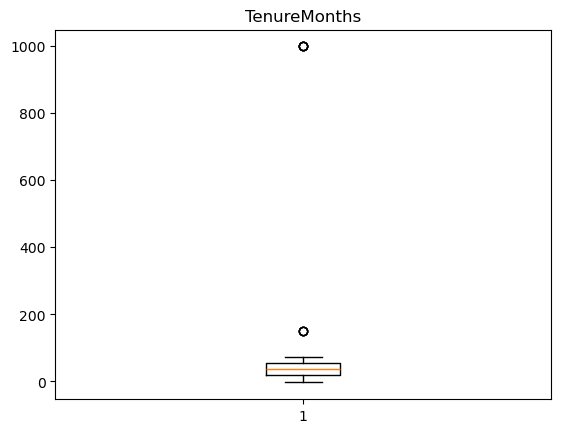

In [39]:
#check outlier using boxplot
plt.boxplot(df['TenureMonths'].dropna())
plt.title('TenureMonths')
plt.show()

In [40]:
#real valid range is 0 to 72 months, The outliers are clearly: -3 (3 rows), 150 (4 rows), 999 (5 rows) = 12 total impossible values.
#Since we know the real valid range from the data itself (0-72), cap using domain logic rather than IQR

df['TenureMonths'] = df['TenureMonths'].clip(lower=0, upper=72)


print(df['TenureMonths'].describe())
print(df['TenureMonths'].value_counts().sort_index())

count    5463.000000
mean       36.039539
std        21.084360
min         0.000000
25%        18.000000
50%        36.000000
75%        54.000000
max        72.000000
Name: TenureMonths, dtype: float64
TenureMonths
0     65
1     81
2     77
3     96
4     74
      ..
68    83
69    66
70    72
71    71
72    89
Name: count, Length: 73, dtype: int64


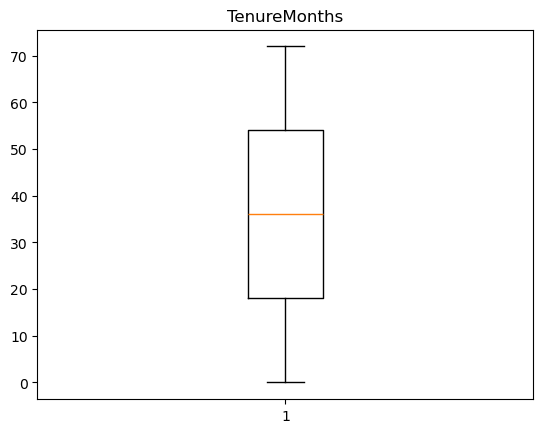

In [41]:
# now show min=0, max=72, with the -3 rows becoming 0 and the 150/999 rows becoming 72.
#check outlier using boxplot
plt.boxplot(df['TenureMonths'].dropna())
plt.title('TenureMonths')
plt.show()

## 5. ContractType Column

In [43]:
# first check this column contain which type of value and null value
print(df['ContractType'].value_counts(dropna=False))

ContractType
Month-to-Month        2946
One Year              1294
Two Year              1048
  Month-to-Month        58
NaN                     43
  One Year              30
  Two Year              22
-                        9
missing                  7
?                        6
Name: count, dtype: int64


In [44]:
#this column contain whitespace duplicates, null-like strings, true nulls.

#strip whitespace
df['ContractType'] = df['ContractType'].str.strip()

#convert null-like strings to real NaN
null_like = ['-', 'missing', '?']
df['ContractType'] = df['ContractType'].replace(null_like, np.nan)


print(df['ContractType'].value_counts(dropna=False))

ContractType
Month-to-Month    3004
One Year          1324
Two Year          1070
NaN                 65
Name: count, dtype: int64


In [45]:
#handle the 65 nulls.
mode_contract = df['ContractType'].mode()[0]
df['ContractType'] = df['ContractType'].fillna(mode_contract)


print("Nulls : ", df['ContractType'].isna().sum())
print(df['ContractType'].value_counts())

Nulls :  0
ContractType
Month-to-Month    3069
One Year          1324
Two Year          1070
Name: count, dtype: int64


## 6. InternetService Column

In [47]:
# first check this column contain which type of value and null value
print(df['InternetService'].value_counts(dropna = False))

InternetService
Fiber Optic    2403
DSL            1906
No             1088
NaN              48
-                 8
missing           5
?                 5
Name: count, dtype: int64


In [48]:
# Convert null-like strings to real NaN
null_like = ['-', 'missing', '?']
df['InternetService'] = df['InternetService'].replace(null_like, np.nan)


print(df['InternetService'].value_counts(dropna = False))

InternetService
Fiber Optic    2403
DSL            1906
No             1088
NaN              66
Name: count, dtype: int64


In [49]:
# 66 null value replace with column mode value
mode_internet = df['InternetService'].mode()[0]
df['InternetService'] = df['InternetService'].fillna(mode_internet)

print("Nulls : ", df['InternetService'].isna().sum())
print(df['InternetService'].value_counts(dropna = False))

Nulls :  0
InternetService
Fiber Optic    2469
DSL            1906
No             1088
Name: count, dtype: int64


## 7. TechSupport column

In [51]:
print(df['TechSupport'].value_counts(dropna=False))

TechSupport
No             2656
Yes            1500
No Internet    1170
NaN             137
Name: count, dtype: int64


In [52]:
#this column contain 137 true null value repalce null value by mode
mode_techsupport = df['TechSupport'].mode()[0]
df['TechSupport'] = df['TechSupport'].fillna(mode_techsupport)


print("Nulls :",df['TechSupport'].isna().sum())
print(df['TechSupport'].value_counts())

Nulls : 0
TechSupport
No             2793
Yes            1500
No Internet    1170
Name: count, dtype: int64


## 8. PaperlessBilling column

In [54]:
print(df['PaperlessBilling'].value_counts(dropna=False))

PaperlessBilling
Yes    3211
No     2171
NaN      81
Name: count, dtype: int64


In [55]:
#replace null value with mode

mode_billing = df['PaperlessBilling'].mode()[0]
df['PaperlessBilling'] = df['PaperlessBilling'].fillna(mode_billing)


print("Nulls :", df['PaperlessBilling'].isna().sum())
print(df['PaperlessBilling'].value_counts())

Nulls : 0
PaperlessBilling
Yes    3292
No     2171
Name: count, dtype: int64


## 9. PaymentMethod  column

In [57]:
print(df['PaymentMethod'].value_counts(dropna=False))

PaymentMethod
Credit Card         1302
Bank Transfer       1291
Mailed Check        1273
Electronic Check    1266
NaN                  205
bank transfer         29
electronic check      29
credit card           27
mailed check          18
?                      9
-                      8
missing                6
Name: count, dtype: int64


In [58]:
#standardize casing
df['PaymentMethod'] = df['PaymentMethod'].str.strip().str.title()

#convert null-like strings to real NaN
null_like = ['?', '-', 'Missing']
df['PaymentMethod'] = df['PaymentMethod'].replace(null_like, np.nan)


print(df['PaymentMethod'].value_counts(dropna=False))

PaymentMethod
Credit Card         1329
Bank Transfer       1320
Electronic Check    1295
Mailed Check        1291
NaN                  228
Name: count, dtype: int64


In [59]:
#now handle null value
#replace null by mode
mode_payment = df['PaymentMethod'].mode()[0]
df['PaymentMethod'] = df['PaymentMethod'].fillna(mode_payment)

# verify
print("Nulls :",df['PaymentMethod'].isna().sum())
print(df['PaymentMethod'].value_counts())

Nulls : 0
PaymentMethod
Credit Card         1557
Bank Transfer       1320
Electronic Check    1295
Mailed Check        1291
Name: count, dtype: int64


## 10. MonthlyCharges column

In [61]:
#this column contain numeric value. first check datatype,null,unique
print("Data Type :",df['MonthlyCharges'].dtype)
print("Nulls :",df['MonthlyCharges'].isna().sum())
print(df['MonthlyCharges'].unique()[:200])

Data Type : object
Nulls : 109
['44.17' '18.0' '69.17' '60.19' '57.4' '55.2' '51.43' '57.0' '62.18'
 '97.78' '22.95' '82.42' '46.12' '67.73' '82.79' '82.52' '62.38' '76.73'
 '40.31' '78.27' '76.89' '72.47' '84.21' '37.95' '53.62' '63.28' '50.16'
 '79.28' '80.57' '72.13' '59.78' '66.04' '77.79' '94.0' '94.5' '81.21'
 '95.88' '82.24' '60.43' '28.48' '63.39' '89.28' '82.36' '56.28' '77.0'
 '65.67' '19.46' '27.36' '72.86' '112.26' '46.83' '21.65' '64.14' '82.43'
 '94.43' '53.96' '$18.00' '100.52' '85.33' '53.45' '91.05' '75.16' '18.24'
 '28.3' '39.44' '46.27' '81.3' '20.52' '58.54' '83.38' '26.83' '62.3'
 '62.72' '93.95' '91.25' '66.66' '18.74' '80.45' '25.06' '94.54' '49.01'
 '62.07' '60.38' '45.07' '82.44' '55.33' '82.74' '94.22' '21.46' '86.0'
 '90.78' '54.06' '50.88' '51.68' '83.84' '24.09' '79.41' '19.18' '19.43'
 '80.22' '86.15' '57.03' '52.22' '93.16' '96.12' '66.5' '85.31' '59.08'
 '97.96' '116.17' '103.03' '89.94' '91.78' '20.68' '53.91' '73.22' '18.3'
 '89.86' '59.46' '64.44' '76

In [62]:
#mix of plain numbers stored as text, some rows have "$" symbols.
#remove the $ symbol, then convert to numeric 
df['MonthlyCharges'] = df['MonthlyCharges'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
df['MonthlyCharges'] = pd.to_numeric(df['MonthlyCharges'], errors='coerce')


print(df['MonthlyCharges'].dtype)
print("Nulls :",df['MonthlyCharges'].isna().sum())

float64
Nulls : 109


In [63]:
#check the Outlier present in this column
print(df['MonthlyCharges'].describe())

count    5354.000000
mean       66.692771
std        86.815877
min        18.000000
25%        46.942500
50%        65.580000
75%        83.810000
max      2980.630578
Name: MonthlyCharges, dtype: float64


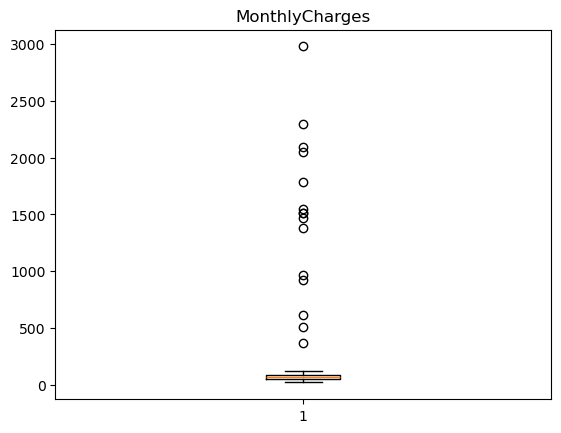

In [64]:
#max of 2980 is clearly the outliers also check with boxplot

plt.boxplot(df['MonthlyCharges'].dropna())
plt.title('MonthlyCharges')
plt.show()

In [65]:
#handle Outlier With IQR Capping

Q1 = df['MonthlyCharges'].quantile(0.25)
Q3 = df['MonthlyCharges'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df['MonthlyCharges'] = df['MonthlyCharges'].clip(lower=lower, upper=upper)


print(df['MonthlyCharges'].describe())

count    5354.000000
mean       62.972032
std        26.252509
min        18.000000
25%        46.942500
50%        65.580000
75%        83.810000
max       139.111250
Name: MonthlyCharges, dtype: float64


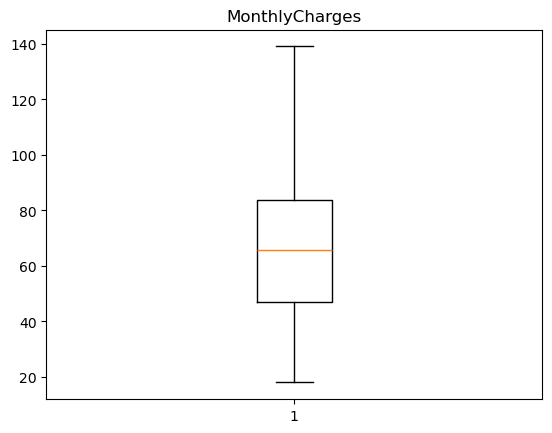

In [66]:
# now check Outlier with BoxPlot

plt.boxplot(df['MonthlyCharges'].dropna())
plt.title('MonthlyCharges')
plt.show()

In [67]:
# Now handle the 109 nulls left in this column
#fill null value by Median 

df['MonthlyCharges'] = df['MonthlyCharges'].fillna(df['MonthlyCharges'].median())


print("Nulls :",df['MonthlyCharges'].isna().sum())
print(df['MonthlyCharges'].describe())

Nulls : 0
count    5463.000000
mean       63.024067
std        25.991799
min        18.000000
25%        47.600000
50%        65.580000
75%        83.375000
max       139.111250
Name: MonthlyCharges, dtype: float64


## 11. TotalCharges Column

In [69]:
#this column contain numeric value. first check datatype,null,unique
print("Data Type :",df['TotalCharges'].dtype)
print("Nulls :",df['TotalCharges'].isna().sum())
print(df['TotalCharges'].unique()[:50])

Data Type : object
Nulls : 0
['1708.56' '666.5' '4990.33' '2154.59' '2999.28' '3343.84' '2822.45'
 '2596.31' '1522.96' '4917.85' '342.63' '2159.33' '2230.84' '3985.72'
 '3991.76' '4322.47' ' ' '433.17' '1107.8' '2188.77' '2059.2' '1672.76'
 '1099.27' '3436.24' '467.32' '2016.36' '3791.3' '3058.54' '1360.99'
 '593.25' '1104.52' '1134.87' '3738.43' '131.09' '4803.7' '485.44'
 '1122.43' '4911.21' '4103.64' '5475.74' '680.37' '695.66' '985.16'
 '2206.64' '3969.06' '2722.7' '2422.52' '2802.71' '240.96' '280.17']


In [70]:
#object dtype and 0 nulls — but this column has blank strings " " for tenure = 0 customers, which won't show up as isna() since they're not true NaN.

blanks = df[df['TotalCharges'].astype(str).str.strip() == '']
print("Blank string rows:", len(blanks))
print(blanks[['TenureMonths', 'TotalCharges']].head(10))

Blank string rows: 62
     TenureMonths TotalCharges
16              0             
83              0             
114             0             
218             0             
316             0             
333             0             
361             0             
523             0             
579             0             
670             0             


In [71]:
#Convert to numeric first, then impute those as 0 — not the mean/median, since it's not truly missing, it's structurally zero.

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)


print("Data Type :",df['TotalCharges'].dtype)
print("Nulls :",df['TotalCharges'].isna().sum())

Data Type : float64
Nulls : 0


## 12. Churn Column

In [73]:
#check which type of values in this column
print(df['Churn'].value_counts(dropna=False))

Churn
No     4225
Yes    1238
Name: count, dtype: int64


In [74]:
#this colunm not contain any missing or null value it contain only valid value

In [75]:
#final shape Of dataset
df.shape

(5463, 12)

### Entire dataset is now fully cleaned.
- save cleaned dataset

In [77]:
df.to_csv('telco_churn_cleaned.csv', index=False)

# 3. EDA = Exploratory Data Analysis

In [79]:
# Basic overview
print("Shape :",df.shape)
print(df.info())
df.describe()

Shape : (5463, 12)
<class 'pandas.core.frame.DataFrame'>
Index: 5463 entries, 0 to 5499
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        5463 non-null   object 
 1   Gender            5463 non-null   object 
 2   SeniorCitizen     5463 non-null   int64  
 3   TenureMonths      5463 non-null   int64  
 4   ContractType      5463 non-null   object 
 5   InternetService   5463 non-null   object 
 6   TechSupport       5463 non-null   object 
 7   PaperlessBilling  5463 non-null   object 
 8   PaymentMethod     5463 non-null   object 
 9   MonthlyCharges    5463 non-null   float64
 10  TotalCharges      5463 non-null   float64
 11  Churn             5463 non-null   object 
dtypes: float64(2), int64(2), object(8)
memory usage: 554.8+ KB
None


,SeniorCitizen,TenureMonths,MonthlyCharges,TotalCharges
count,5463.000000,5463.000000,5463.000000,5463.000000
mean,0.158338,36.039539,63.024067,2202.330533
std,0.365091,21.084360,25.991799,1674.357343
min,0.000000,0.000000,18.000000,0.000000
25%,0.000000,18.000000,47.600000,810.115000
50%,0.000000,36.000000,65.580000,1818.980000
75%,0.000000,54.000000,83.375000,3382.365000
max,1.000000,72.000000,139.111250,8022.890000


In [80]:
#this confirms everything is clean: no nulls, all correct dtypes

## 1. Univariate Analysis

### Univariate : Target distribution

Churn
No     77.338459
Yes    22.661541
Name: proportion, dtype: float64


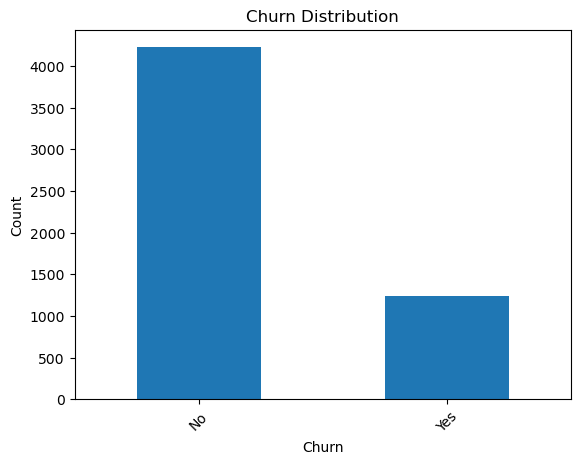

In [83]:
print(df['Churn'].value_counts(normalize=True) * 100)

df['Churn'].value_counts().plot(kind='bar', title='Churn Distribution')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

### Univariate : Numeric distributions

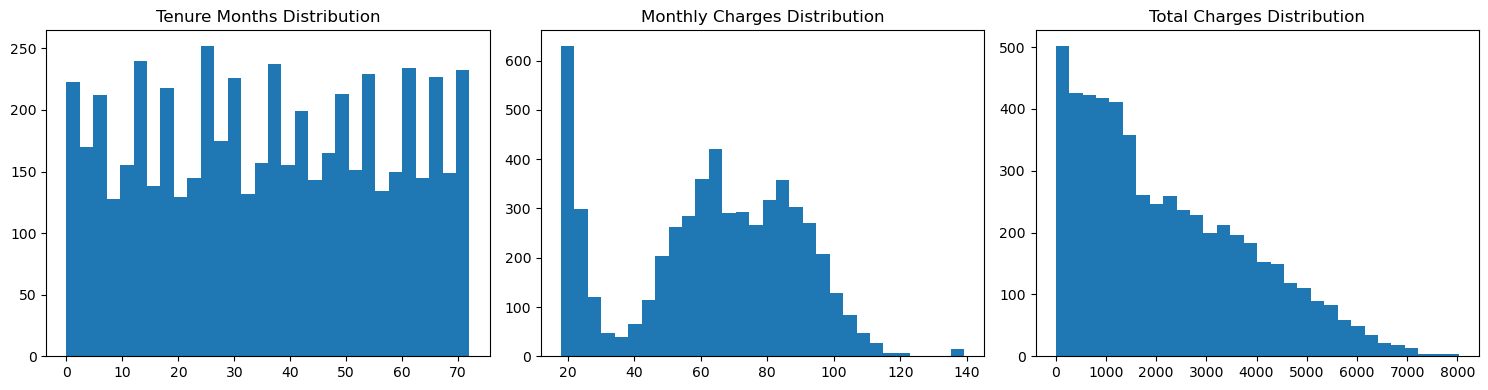

In [85]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df['TenureMonths'], bins=30)
axes[0].set_title('Tenure Months Distribution')

axes[1].hist(df['MonthlyCharges'], bins=30)
axes[1].set_title('Monthly Charges Distribution')

axes[2].hist(df['TotalCharges'], bins=30)
axes[2].set_title('Total Charges Distribution')

plt.tight_layout()
plt.show()

## 2. Bivariate Analysis
### A. Churn rate by category

#### 1. Churn rate by ContractType

Churn                  No        Yes
ContractType                        
Month-to-Month  72.434018  27.565982
One Year        82.250755  17.749245
Two Year        85.327103  14.672897


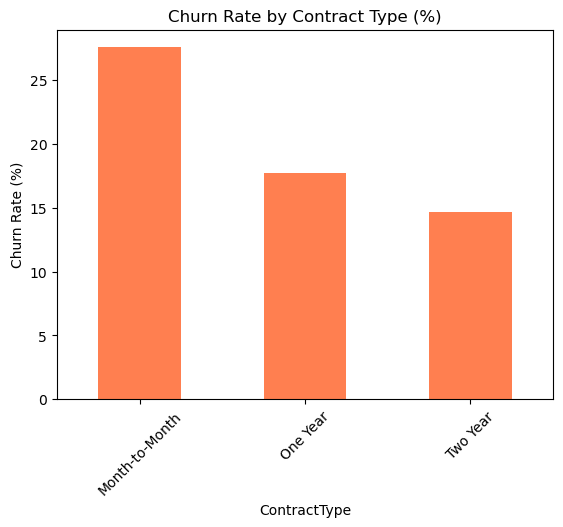

In [88]:
contract_churn = df.groupby('ContractType')['Churn'].value_counts(normalize=True).unstack() * 100
print(contract_churn)

contract_churn['Yes'].plot(kind='bar', title='Churn Rate by Contract Type (%)', color='coral')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

##### Churn Rate by Contract Type

- Month-to-Month: ~27% (highest)
- One Year: ~18%
- Two Year: ~15% (lowest)

Customers on Month-to-Month contracts churn at nearly double the rate of those on Two Year contracts. This is the strongest single churn driver in the dataset — shorter commitment periods give customers an easy, low-friction opportunity to leave at any time, while longer contracts create switching inertia.

#### 2. Churn rate by InternetService

Churn                   No        Yes
InternetService                      
DSL              81.951731  18.048269
Fiber Optic      70.473876  29.526124
No               84.834559  15.165441


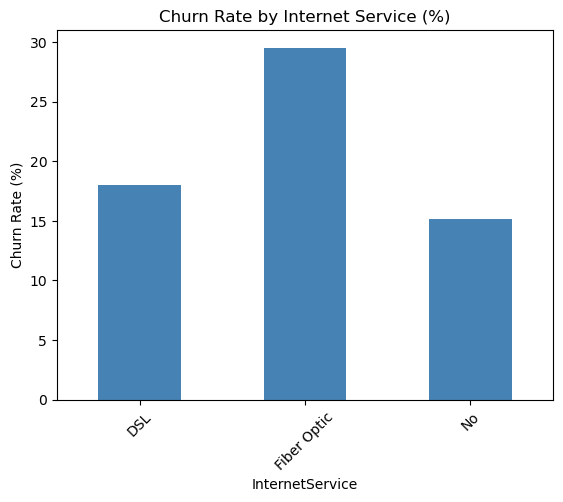

In [91]:
internet_churn = df.groupby('InternetService')['Churn'].value_counts(normalize=True).unstack() * 100
print(internet_churn)

internet_churn['Yes'].plot(kind='bar', title='Churn Rate by Internet Service (%)', color='steelblue')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

#####  Churn Rate by Internet Service

- Fiber Optic: ~29% (highest)
- DSL: ~18%
- No Internet: ~15% (lowest)

Fiber Optic customers churn significantly more than DSL or no-internet customers. This likely reflects a mix of higher price sensitivity (Fiber Optic is typically the most expensive tier) and possibly service quality issues — worth flagging as a retention priority segment.

#### 3. Churn rate by PaymentMethod

Churn                    No        Yes
PaymentMethod                         
Bank Transfer     77.878788  22.121212
Credit Card       78.291586  21.708414
Electronic Check  73.976834  26.023166
Mailed Check      79.008521  20.991479


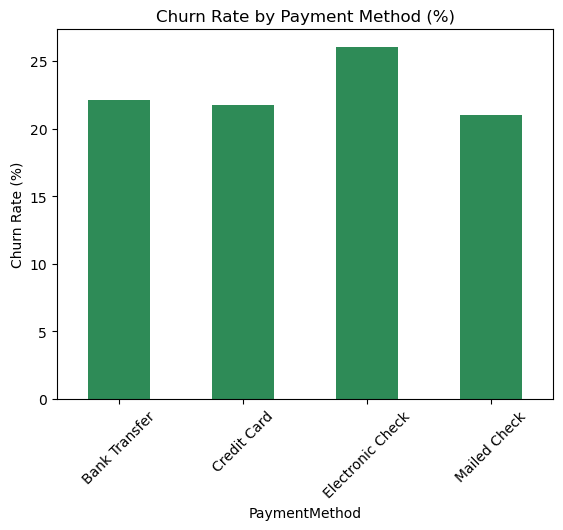

In [94]:
payment_churn = df.groupby('PaymentMethod')['Churn'].value_counts(normalize=True).unstack() * 100
print(payment_churn)

payment_churn['Yes'].plot(kind='bar', title='Churn Rate by Payment Method (%)', color='seagreen')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

#####  Churn Rate by Payment Method

- Electronic Check: ~26% (highest)
- Bank Transfer: ~22%
- Credit Card: ~21.5%
- Mailed Check: ~21%

Electronic Check users show a noticeably higher churn rate than other payment methods. This is a well-known pattern in churn analysis — customers on manual/non-automatic payment methods tend to be less "locked in" and more prone to switching providers compared to those on auto-pay (Credit Card, Bank Transfer).

In [96]:
#The combination of these three factors — Month-to-Month + Fiber Optic + Electronic Check
df['HighRiskCombo'] = (
    (df['ContractType'] == 'Month-to-Month') &
    (df['InternetService'] == 'Fiber Optic') &
    (df['PaymentMethod'] == 'Electronic Check')
).astype(int)

print(df['HighRiskCombo'].value_counts())
print(df.groupby('HighRiskCombo')['Churn'].value_counts(normalize=True))

HighRiskCombo
0    5128
1     335
Name: count, dtype: int64
HighRiskCombo  Churn
0              No       0.784126
               Yes      0.215874
1              No       0.608955
               Yes      0.391045
Name: proportion, dtype: float64


#### Insight
- Overall churn rate: ~22.6%
- High-risk segment (Month-to-Month + Fiber Optic + Electronic Check): 39.1% churn
- Everyone else: 21.6% churn
  
Customers who simultaneously have a Month-to-Month contract, Fiber Optic internet, and pay via Electronic Check show a churn rate of 39.1% — nearly double the overall average of 22.6%. Although this segment represents only ~6% of the customer base, it accounts for a disproportionate share of churn risk, making it a high-priority target for retention campaigns

In [98]:
#Revenue impact
high_risk_revenue = df[df['HighRiskCombo']==1]['MonthlyCharges'].sum()
print(f"Monthly revenue from high-risk segment: ${high_risk_revenue:,.2f}")
print(f"Potential monthly revenue loss if all churn: ${df[(df['HighRiskCombo']==1) & (df['Churn']=='Yes')]['MonthlyCharges'].sum():,.2f}")

Monthly revenue from high-risk segment: $27,974.36
Potential monthly revenue loss if all churn: $10,835.88


### B. Numeric columns vs Churn

#### TenureMonths vs Churn

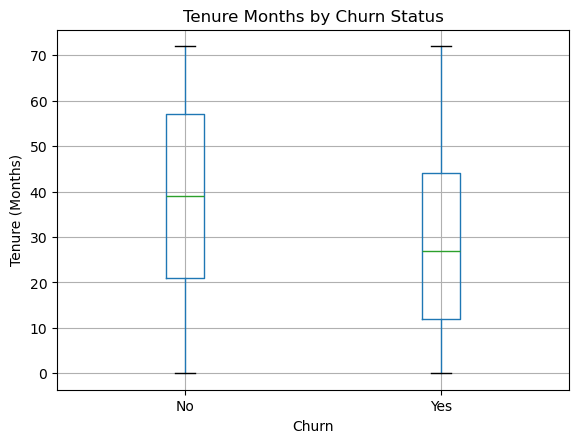

In [101]:
df.boxplot(column='TenureMonths', by='Churn')
plt.title('Tenure Months by Churn Status')
plt.suptitle('')
plt.ylabel('Tenure (Months)')
plt.show()

##### This boxplot compares how long customers stayed before churning vs. those who didn't. Customers who churn typically have shorter tenure, while long-tenured customers are more likely to stay — showing that churn risk is highest early in the customer relationship.

#### MonthlyCharges vs Churn

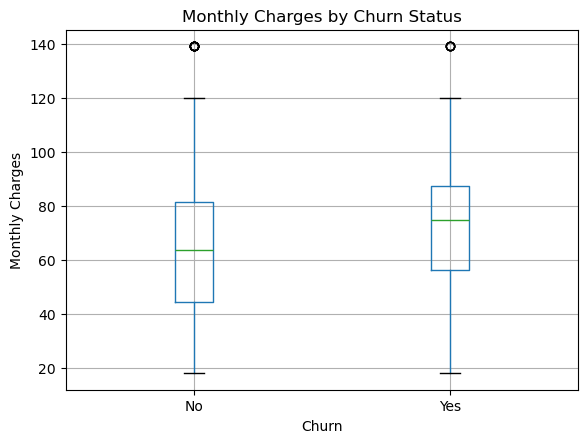

In [104]:
df.boxplot(column='MonthlyCharges', by='Churn')
plt.title('Monthly Charges by Churn Status')
plt.suptitle('')
plt.ylabel('Monthly Charges')
plt.show()

##### This boxplot compares monthly billing amounts between churned and retained customers. If churned customers show higher median charges, it suggests price sensitivity is a contributing factor to churn.

## 3. Correlation heatmap

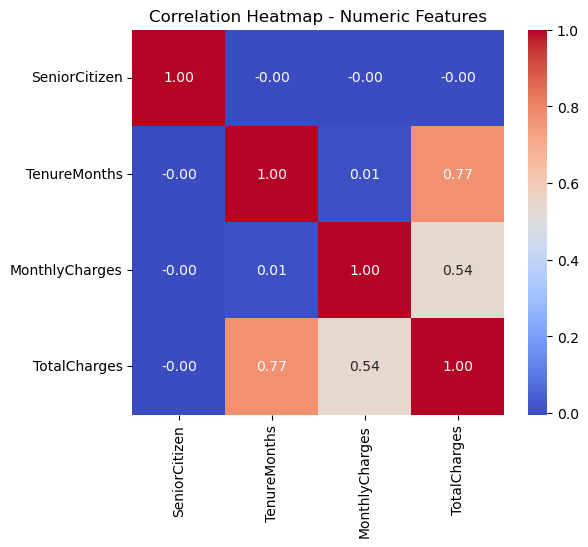

In [107]:
numeric_cols = ['SeniorCitizen', 'TenureMonths', 'MonthlyCharges', 'TotalCharges']
corr = df[numeric_cols].corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap - Numeric Features')
plt.show()

##### This heatmap shows how strongly the numeric features relate to each other. A high correlation between TenureMonths and TotalCharges is expected (longer-tenured customers naturally accumulate higher total charges) — this is useful to know before modeling, since highly correlated features can sometimes be redundant.